In [18]:
import pandas as pd
import json
import matplotlib.pyplot as plt

In [2]:
csv_data = pd.DataFrame({
    'OrderID':[101,102,103],
    'Product':['Laptop','Mouse','Keyboard'],
    'Quantity':[2,5,None],
    'Price':[50000,500,1500]
})

In [3]:
csv_data.to_csv('sales.csv',index=False)

In [4]:
excel_data=pd.DataFrame({
    'OrderID':[104,105,102],
    'Product':['Monitor','mouse','Mouse'],
    'Quantity':[1,3,5],
    'Price':[12000,500,500]
})
excel_data.to_excel('sales.xlsx',index=False)

json_data=[
    {'OrderID':106,'Product':'Laptop',
     'Quantity':1,'Price':50000},
    {'OrderID':107,'Product':'keyboard',
     'Quantity':2,'Price':1500}
]

with open('sales.json','w') as file:
    json.dump(json_data,file,indent=4)

print("All three sales file created successfully!")


All three sales file created successfully!


In [5]:
df_csv=pd.read_csv('sales.csv')
df_excel=pd.read_excel('sales.xlsx')
df_json=pd.read_json('sales.json')

print("csv Data:")
display(df_csv)

print("Excel Data:")
display(df_excel)

print("Json Data:")
display(df_json)

csv Data:


,OrderID,Product,Quantity,Price
0,101,Laptop,2.0,50000
1,102,Mouse,5.0,500
2,103,Keyboard,NaN,1500


Excel Data:


,OrderID,Product,Quantity,Price
0,104,Monitor,1,12000
1,105,mouse,3,500
2,102,Mouse,5,500


Json Data:


,OrderID,Product,Quantity,Price
0,106,Laptop,1,50000
1,107,keyboard,2,1500


In [8]:
datasets = {
    'csv':df_csv,
    'Excel':df_excel,
    'JSON':df_json
}

for name, df in datasets.items():
    print(f"\n{'=' * 15} {name} DATA {'=' * 15}")

    print("\nFirst Five Rows:")
    display(df.head())

    print("\nColumns Names:")
    print(df.columns.tolist())

    print("\nData types and Non-Null Counts:")
    df.info()

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())


=============== csv DATA ===============

First Five Rows:


,OrderID,Product,Quantity,Price
0,101,Laptop,2.0,50000
1,102,Mouse,5.0,500
2,103,Keyboard,NaN,1500



Columns Names:
['OrderID', 'Product', 'Quantity', 'Price']

Data types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   OrderID   3 non-null      int64  
 1   Product   3 non-null      object 
 2   Quantity  2 non-null      float64
 3   Price     3 non-null      int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 228.0+ bytes

Missing values:
OrderID     0
Product     0
Quantity    1
Price       0
dtype: int64

Duplicate Rows:
0

=============== Excel DATA ===============

First Five Rows:


,OrderID,Product,Quantity,Price
0,104,Monitor,1,12000
1,105,mouse,3,500
2,102,Mouse,5,500



Columns Names:
['OrderID', 'Product', 'Quantity', 'Price']

Data types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   OrderID   3 non-null      int64 
 1   Product   3 non-null      object
 2   Quantity  3 non-null      int64 
 3   Price     3 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 228.0+ bytes

Missing values:
OrderID     0
Product     0
Quantity    0
Price       0
dtype: int64

Duplicate Rows:
0

=============== JSON DATA ===============

First Five Rows:


,OrderID,Product,Quantity,Price
0,106,Laptop,1,50000
1,107,keyboard,2,1500



Columns Names:
['OrderID', 'Product', 'Quantity', 'Price']

Data types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   OrderID   2 non-null      int64 
 1   Product   2 non-null      object
 2   Quantity  2 non-null      int64 
 3   Price     2 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 196.0+ bytes

Missing values:
OrderID     0
Product     0
Quantity    0
Price       0
dtype: int64

Duplicate Rows:
0


In [9]:
sales_data=pd.concat(
    [df_csv,df_excel,df_json],
    ignore_index=True
)

print("Combiined Sales Data:")
display(sales_data)

print("Total Records:",len(sales_data))

Combiined Sales Data:


,OrderID,Product,Quantity,Price
0,101,Laptop,2.0,50000
1,102,Mouse,5.0,500
2,103,Keyboard,NaN,1500
3,104,Monitor,1.0,12000
4,105,mouse,3.0,500
5,102,Mouse,5.0,500
6,106,Laptop,1.0,50000
7,107,keyboard,2.0,1500


Total Records: 8


In [12]:

# Standardize Product names
sales_data['Product'] = (
    sales_data['Product']
    .astype('string')
    .str.strip()
    .str.title()
)

# Convert columns to numeric
for col in ['OrderID', 'Quantity', 'Price']:
    sales_data[col] = pd.to_numeric(
        sales_data[col],
        errors='coerce'
    )

# Remove rows with missing essential values
sales_data = sales_data.dropna(
    subset=['OrderID', 'Product', 'Price']
)

# Remove duplicate OrderIDs
sales_data = sales_data.drop_duplicates(
    subset=['OrderID'],
    keep='first'
)

# Fill missing Quantity with median
sales_data['Quantity'] = sales_data['Quantity'].fillna(
    sales_data['Quantity'].median()
)

# Convert columns to integer
sales_data['OrderID'] = sales_data['OrderID'].astype(int)
sales_data['Quantity'] = sales_data['Quantity'].astype(int)

# Reset index
sales_data = sales_data.reset_index(drop=True)

print("Data cleaning completed successfully!")
display(sales_data)


Data cleaning completed successfully!


,OrderID,Product,Quantity,Price
0,101,Laptop,2,50000
1,102,Mouse,5,500
2,103,Keyboard,2,1500
3,104,Monitor,1,12000
4,105,Mouse,3,500
5,106,Laptop,1,50000
6,107,Keyboard,2,1500


In [13]:
sales_data['TotalSales']=(
    sales_data['Quantity']*sales_data['Price']
)

print("Transformed Sales Data:")
display(sales_data)

Transformed Sales Data:


,OrderID,Product,Quantity,Price,TotalSales
0,101,Laptop,2,50000,100000
1,102,Mouse,5,500,2500
2,103,Keyboard,2,1500,3000
3,104,Monitor,1,12000,12000
4,105,Mouse,3,500,1500
5,106,Laptop,1,50000,50000
6,107,Keyboard,2,1500,3000


In [14]:
print("Descriptive Statistics:")
display(sales_data.describe())

print("Total sales:",sales_data['TotalSales'].sum())

print("Average Order value:",
      sales_data['TotalSales'].mean())

print("\n Product-wise Sales:")
product_sales=sales_data.groupby(
    'Product'
)['TotalSales'].sum().sort_values(ascending=False)

display(product_sales)

Descriptive Statistics:


,OrderID,Quantity,Price,TotalSales
count,7.000000,7.000000,7.000000,7.000000
mean,104.000000,2.285714,16571.428571,24571.428571
std,2.160247,1.380131,23190.207293,37514.917668
min,101.000000,1.000000,500.000000,1500.000000
25%,102.500000,1.500000,1000.000000,2750.000000
50%,104.000000,2.000000,1500.000000,3000.000000
75%,105.500000,2.500000,31000.000000,31000.000000
max,107.000000,5.000000,50000.000000,100000.000000


Total sales: 172000
Average Order value: 24571.428571428572

 Product-wise Sales:


Product
Laptop      150000
Monitor      12000
Keyboard      6000
Mouse         4000
Name: TotalSales, dtype: int64

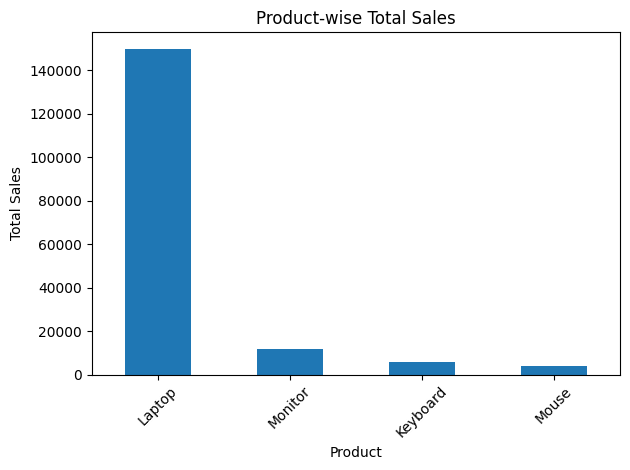

In [19]:
product_sales.plot(
    kind='bar',
    title='Product-wise Total Sales',
    xlabel='Product',
    ylabel='Total Sales'
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

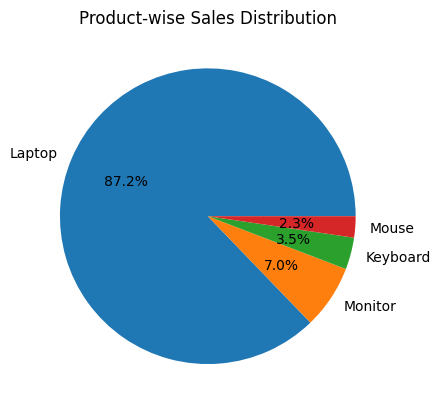

In [20]:
product_sales.plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Product-wise Sales Distribution'
)
plt.ylabel('')
plt.show()

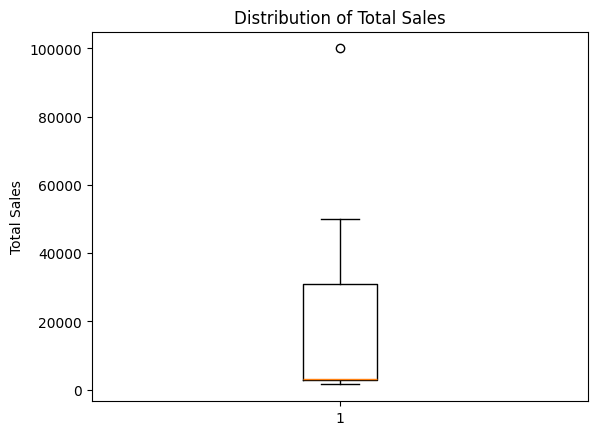

In [21]:
plt.boxplot(sales_data['TotalSales'].dropna())

plt.title('Distribution of Total Sales')
plt.ylabel('Total Sales')
plt.show()
          

In [23]:
sales_data.to_csv(
    'final_cleaned_sales.csv',
    index=False
)
print("Final dataset saved successfully!")

Final dataset saved successfully!
